# Predictive Customer Lifetime Value: Comparing Statistical and Machine Learning Models
**Notebook 2 (Version 5) | Marketing Data Science | Google Colab**

This reproducible experiment forecasts **2025 purchase counts and customer contribution** from the *frozen* synthetic customers generated in Notebook 1. We compare two historical baselines, BG/NBD with Gamma-Gamma, random forest, and histogram gradient boosting. The article should report actual holdout findings, including model limitations, rather than assume an advanced model must win.

**Protocol:** Observation through **2024-12-31**, forecast **2025-01-01 to 2025-12-31**, same 2,000 existing customers throughout. The hidden simulator truth is strictly evaluation-only. Do not retune the simulation after viewing results.

**Important:** These data are synthetic educational examples, not representative industry evidence. This notebook evaluates forecasts, not causal effects.

## 1. Environment and input files
Run this notebook in Google Colab. Upload `customer_profiles.csv`, `calibration_transactions.csv`, `transactions.csv`, and `simulation_metadata.json` (or upload the ZIP from Notebook 1). `simulation_ground_truth.csv` is *optional* and is used only after predictions have been finalized for diagnostic reporting. The probabilistic package `lifetimes` is installed in Colab; if package installation is blocked in another environment, the notebook skips that model with an explicit warning.

In [1]:
# In Colab this installs lifetimes; other dependencies are preinstalled.
import importlib.util, subprocess, sys
if importlib.util.find_spec('lifetimes') is None:
    try:
        subprocess.check_call([sys.executable, '-m', 'pip', '-q', 'install', 'lifetimes'])
    except Exception as e:
        print('lifetimes unavailable; BG/NBD and Gamma-Gamma will be skipped:', e)

In [2]:
from pathlib import Path
import io, json, zipfile, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from IPython.display import display

SEED = 20261012
CAL_END = pd.Timestamp('2024-12-31')
HOLD_END = pd.Timestamp('2025-12-31')
HORIZON_DAYS = (HOLD_END-CAL_END).days
INPUT = Path('/content') if Path('/content').exists() else Path('/mnt/data')
OUTPUT = Path('/content/clv_model_results') if Path('/content').exists() else Path('/mnt/data/clv_model_results')
OUTPUT.mkdir(parents=True, exist_ok=True)
needed = ['customer_profiles.csv', 'calibration_transactions.csv', 'transactions.csv', 'simulation_metadata.json']
if not all((INPUT/f).exists() for f in needed):
    if Path('/content').exists():
        from google.colab import files
        print('Upload the four CSV/JSON files, or the Notebook 1 ZIP.')
        uploaded = files.upload()
        for filename, data in uploaded.items():
            if filename.lower().endswith('.zip'):
                with zipfile.ZipFile(io.BytesIO(data)) as z:
                    for item in z.namelist():
                        if Path(item).name in needed + ['simulation_ground_truth.csv']:
                            (INPUT / Path(item).name).write_bytes(z.read(item))
    else:
        print('Local run: input files expected under', INPUT)
missing = [f for f in needed if not (INPUT/f).exists()]
if missing: raise FileNotFoundError(f'Missing required Notebook 1 exports: {missing}')
profiles = pd.read_csv(INPUT/'customer_profiles.csv', parse_dates=['acquisition_date'])
calibration = pd.read_csv(INPUT/'calibration_transactions.csv', parse_dates=['transaction_date'])
all_transactions = pd.read_csv(INPUT/'transactions.csv', parse_dates=['transaction_date'])
metadata = json.loads((INPUT/'simulation_metadata.json').read_text())
print('Profiles:', profiles.shape, '| calibration:', calibration.shape, '| all transactions:', all_transactions.shape)

Profiles: (2000, 4) | calibration: (25416, 7) | all transactions: (33557, 7)


## 2. Verify the frozen experiment boundary
The only legitimate predictors are customer-profile fields known by the forecast date and transactions dated on/before the relevant origin. The 2025 transaction rows are accessed **only to construct outcome labels and holdout metrics**, never as predictors. Latent simulator parameters are prohibited predictors.

In [3]:
assert metadata['random_seed'] == SEED
assert metadata['calibration_end'] == '2024-12-31' and metadata['holdout_start'] == '2025-01-01'
assert len(profiles)==2000 and profiles.customer_id.is_unique
assert calibration.transaction_id.is_unique and all_transactions.transaction_id.is_unique
assert calibration.transaction_date.max() <= CAL_END
assert (calibration.transaction_date >= pd.Timestamp(metadata['calibration_start'])).all()
assert (all_transactions.query("period == 'holdout'").transaction_date > CAL_END).all()
assert len(all_transactions)==33557 and len(calibration)==25416
assert (all_transactions.contribution >= 0).all()
assert set(calibration.transaction_id).issubset(set(all_transactions.transaction_id))
assert not profiles.columns.isin(['latent_dropout_date','realized_holdout_contribution']).any()
holdout = all_transactions.loc[(all_transactions.transaction_date > CAL_END) & (all_transactions.transaction_date <= HOLD_END)].copy()
assert len(holdout)==8141
print('PASS: Frozen dates, dataset counts, identifiers, and leakage safeguards.')

PASS: Frozen dates, dataset counts, identifiers, and leakage safeguards.


## 3. Build features from a cutoff date
**Recency** here means *days since the last observed purchase* (a common ML/RFM usage). In `lifetimes`, `recency` instead means *time from first to last observed transaction*. We deliberately use different names for these different definitions.

Customers who joined late have shorter observed exposure; all rate features divide by the number of days since acquisition. Features never read transactions after the cutoff.

In [4]:
def features_at(cutoff, eligible=None):
    cutoff = pd.Timestamp(cutoff)
    p = profiles.loc[profiles.acquisition_date <= cutoff].copy()
    if eligible is not None: p = p[p.customer_id.isin(set(eligible))].copy()
    t = calibration.loc[calibration.transaction_date <= cutoff].copy()
    t = t[t.customer_id.isin(set(p.customer_id))]
    g = t.groupby('customer_id').agg(
        purchases=('transaction_id','count'), distinct_purchase_days=('transaction_date','nunique'),
        first_purchase=('transaction_date','min'), last_purchase=('transaction_date','max'),
        revenue=('revenue','sum'), contribution=('contribution','sum'),
        mean_revenue=('revenue','mean'), mean_contribution=('contribution','mean'),
        std_revenue=('revenue','std'), std_contribution=('contribution','std'))
    p = p.join(g, on='customer_id')
    p['exposure_days'] = (cutoff-p.acquisition_date).dt.days.clip(lower=0)+1
    p['days_since_last_purchase'] = (cutoff-p.last_purchase).dt.days.fillna(p.exposure_days)
    p['customer_tenure_days'] = p.exposure_days
    for days in [90,180,365]:
        agg = t.loc[t.transaction_date > cutoff-pd.Timedelta(days=days)].groupby('customer_id').agg(
            **{f'count_{days}d':('transaction_id','count'), f'contribution_{days}d':('contribution','sum')})
        p = p.join(agg, on='customer_id')
    p['purchases_per_year'] = p.purchases.fillna(0)*365.25 / p.exposure_days
    p['contribution_per_year'] = p.contribution.fillna(0)*365.25 / p.exposure_days
    p['observed_margin'] = (p.contribution / p.revenue.replace(0,np.nan)).fillna(0)
    numeric = p.select_dtypes(include='number').columns
    p[numeric] = p[numeric].fillna(0)
    return p.drop(columns=['first_purchase','last_purchase'])

def outcomes_between(start_exclusive, end_inclusive, ids):
    sub = all_transactions.loc[(all_transactions.transaction_date > pd.Timestamp(start_exclusive)) &
                               (all_transactions.transaction_date <= pd.Timestamp(end_inclusive))]
    agg = sub.groupby('customer_id').agg(actual_purchases=('transaction_id','size'),
                                         actual_contribution=('contribution','sum'),
                                         actual_revenue=('revenue','sum'))
    return pd.DataFrame({'customer_id':list(ids)}).merge(agg,on='customer_id',how='left').fillna(0)

X_hold = features_at(CAL_END)
y_hold = outcomes_between(CAL_END, HOLD_END, X_hold.customer_id)
assert (X_hold.acquisition_date <= CAL_END).all()
print('Forecast customers:',len(X_hold),'| customer purchases in 2025:', (y_hold.actual_purchases>0).sum())
display(X_hold[['customer_id','segment','purchases','days_since_last_purchase','purchases_per_year','contribution_per_year']].head())

Forecast customers: 2000 | customer purchases in 2025: 865


,customer_id,segment,purchases,days_since_last_purchase,purchases_per_year,contribution_per_year
0,C00001,Regular,1,1059,0.344575,27.824469
1,C00002,Occasional,1,551,0.661685,47.747174
2,C00003,Enthusiast,19,16,23.604592,1167.346454
3,C00004,Regular,16,376,6.197243,301.813473
4,C00005,Regular,20,20,8.207865,358.293834


## 4. RFM exploration and historical baselines
We use transaction frequency and monetary contribution along with recency to describe the customer base. Baselines: **lifetime exposure-adjusted annual run rate** and **last-365-day run rate**. Both forecast exactly one year and use no future information. They are intentionally simple and may overpredict when attrition is important.

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
customer_id,2000,2000,C01984,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
segment,2000,3,Occasional,990,NaN,NaN,NaN,NaN,NaN,NaN,NaN
days_since_last_purchase,2000.0,NaN,NaN,NaN,286.8775,297.706581,0.0,34.0,166.0,486.0,1094.0
purchases,2000.0,NaN,NaN,NaN,12.708,14.860187,1.0,4.0,8.0,16.0,138.0
mean_contribution,2000.0,NaN,NaN,NaN,51.691421,27.787384,3.76,31.959952,46.040625,64.473722,248.765
contribution,2000.0,NaN,NaN,NaN,629.74769,870.388227,3.76,160.145,346.115,736.1675,11929.99


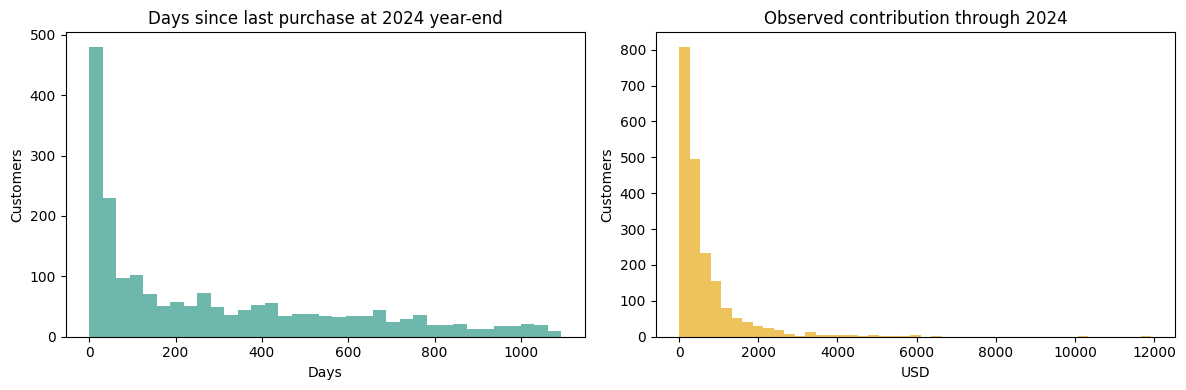

In [5]:
rfm = X_hold[['customer_id','segment','days_since_last_purchase','purchases','mean_contribution','contribution']].copy()
display(rfm.describe(include='all').T)
fig, axes = plt.subplots(1,2,figsize=(12,4))
axes[0].hist(X_hold.days_since_last_purchase,bins=35,color='#6db7ac')
axes[0].set(title='Days since last purchase at 2024 year-end',xlabel='Days',ylabel='Customers')
axes[1].hist(X_hold.contribution,bins=45,color='#eec35b')
axes[1].set(title='Observed contribution through 2024',xlabel='USD',ylabel='Customers')
plt.tight_layout();plt.show()

preds = X_hold[['customer_id','segment','acquisition_channel']].copy()
preds['actual_purchases'] = y_hold.actual_purchases.to_numpy()
preds['actual_contribution'] = y_hold.actual_contribution.to_numpy()
preds['actual_revenue'] = y_hold.actual_revenue.to_numpy()
preds['Baseline lifetime_purchases'] = X_hold.purchases_per_year.to_numpy()
preds['Baseline lifetime_contribution'] = X_hold.contribution_per_year.to_numpy()
preds['Baseline recent_purchases'] = X_hold.count_365d.to_numpy()
preds['Baseline recent_contribution'] = X_hold.contribution_365d.to_numpy()

## 5. Probabilistic model: BG/NBD and Gamma-Gamma
BG/NBD predicts future **repeat purchases** for noncontractual customers. The first purchase is treated as acquisition, and multiple same-day transactions are **aggregated to one purchase occasion** for this model (with their revenues/contributions summed), rather than treated as multiple independent interpurchase intervals. This differs from the raw transaction-count target: we therefore report both raw purchase-count metrics for baselines/ML and a matched **purchase-occasion** comparison for BG/NBD.

Gamma-Gamma estimates contribution **per repeat occasion**, using strictly positive contributions. Its critical independence assumption (frequency versus average monetary value) is checked with Spearman correlation. Standard models may be misspecified because Notebook 1 simulates seasonality and heterogeneous customer behavior; a poor result is informative, not a bug. `lifetimes` represents duration in **days** throughout.

For customers with no repeat purchase occasions, the Gamma-Gamma monetary prediction is not identified from repeat behavior. We use the **calibration-period mean repeat-occasion contribution among eligible customers** as a clearly labeled fallback. This is an empirical approximation, not a fitted Gamma-Gamma estimate for these customers. The models and fallback never see holdout labels.

**Numerical validation:** We report optimization warnings, check every prediction for missing or nonfinite values, and never silently replace an invalid BG/NBD forecast with zero. Customers without repeat occasions receive an *empirical fallback*, not an individualized Gamma-Gamma forecast.


In [6]:
# BG/NBD + Gamma-Gamma: consistent purchase-occasion summaries
from lifetimes import BetaGeoFitter, GammaGammaFitter
from lifetimes.utils import summary_data_from_transaction_data

# Use calibration transactions ONLY; normalize timestamps to calendar dates.
cal = calibration.copy()
cal['transaction_date'] = pd.to_datetime(cal['transaction_date']).dt.normalize()
assert (cal.transaction_date <= CAL_END).all()

# Treat multiple same-day transactions as one purchase occasion.
cal_days = cal.groupby(['customer_id', 'transaction_date'], as_index=False).agg(
    contribution=('contribution', 'sum'))
summ = summary_data_from_transaction_data(
    cal_days, customer_id_col='customer_id', datetime_col='transaction_date',
    monetary_value_col='contribution', observation_period_end=CAL_END, freq='D')

# BG/NBD recency means time from first to last purchase (not days since last purchase).
assert len(summ) == len(X_hold)
assert (summ.recency <= summ['T']).all() and (summ.recency >= 0).all()
assert (summ.loc[summ.frequency == 0, 'recency'] == 0).all()
print('BG/NBD input validation: PASS | Customers:', len(summ))

gg_eligible = (summ.frequency > 0) & (summ.monetary_value > 0)
rho, pval = spearmanr(summ.loc[gg_eligible, 'frequency'],
                      summ.loc[gg_eligible, 'monetary_value'])
print(f'Gamma-Gamma eligibility: {gg_eligible.sum()} / {len(summ)} | '
      f'Spearman(frequency, mean repeat contribution): {rho:.3f}, p={pval:.4g}')

# Log-related RuntimeWarnings can originate inside numerical optimization.
# Record and report them; do not suppress or assume invalid output.
with warnings.catch_warnings(record=True) as fit_warnings:
    warnings.simplefilter('always', RuntimeWarning)
    # Increased penalizer_coef from 0.1 to 1.0 to stabilize BG/NBD likelihood optimization
    bgf = BetaGeoFitter(penalizer_coef=1.0)
    bgf.fit(summ.frequency, summ.recency, summ['T'])
print('BG/NBD fit RuntimeWarnings:',
      [str(w.message) for w in fit_warnings if issubclass(w.category, RuntimeWarning)])
summ['BGNBD_occasions'] = bgf.conditional_expected_number_of_purchases_up_to_time(
    HORIZON_DAYS, summ.frequency, summ.recency, summ['T'])
# Missing or nonfinite predictions are errors, not zero expected purchases.
raw_bg = summ['BGNBD_occasions'].to_numpy(dtype=float)
print('BG/NBD nonfinite expectations:', int((~np.isfinite(raw_bg)).sum()))
if not np.isfinite(raw_bg).all() or (raw_bg < 0).any():
    raise ValueError('BG/NBD generated invalid expected purchase counts; inspect inputs and fit.')
print('BG/NBD fitting: PASS')

with warnings.catch_warnings(record=True) as gg_warnings:
    warnings.simplefilter('always', RuntimeWarning)
    ggf = GammaGammaFitter(penalizer_coef=0.1)
    ggf.fit(summ.loc[gg_eligible, 'frequency'], summ.loc[gg_eligible, 'monetary_value'])
print('Gamma-Gamma fit RuntimeWarnings:',
      [str(w.message) for w in gg_warnings if issubclass(w.category, RuntimeWarning)])

# Apply Gamma-Gamma ONLY to eligible customers; avoids invalid log(0) inputs.
summ['predicted_contribution_per_occasion'] = np.nan
summ.loc[gg_eligible, 'predicted_contribution_per_occasion'] = (
    ggf.conditional_expected_average_profit(
        summ.loc[gg_eligible, 'frequency'], summ.loc[gg_eligible, 'monetary_value']))
monetary_fallback = summ.loc[gg_eligible, 'monetary_value'].mean()
assert np.isfinite(monetary_fallback) and monetary_fallback > 0
print(f'Empirical mean repeat-occasion contribution fallback for {int((~gg_eligible).sum())} ineligible customers: ${monetary_fallback:,.2f}')
summ['predicted_contribution_per_occasion'] = (
    summ['predicted_contribution_per_occasion'].fillna(monetary_fallback))
summ['BGNBD_GammaGamma_contribution'] = (
    summ.BGNBD_occasions * summ.predicted_contribution_per_occasion)
if not np.isfinite(summ[['predicted_contribution_per_occasion',
                         'BGNBD_GammaGamma_contribution']].to_numpy(dtype=float)).all():
    raise ValueError('Invalid monetary predictions; do not replace missing values with zero.')

# FOLLOW-UP EXPLORATORY HYBRID (added after inspecting the 2025 holdout):
# Predict purchase occasions with the ORIGINAL BG/NBD fit and their monetary
# contribution using calibration-period customer history. Not a fresh holdout test.
# Repeat purchasers: observed mean contribution per repeat occasion.
# Zero-repeat customers: their one observed first purchase provides a customer-
# specific estimate; fall back to calibration population average only if missing.
first_occ = cal_days.sort_values('transaction_date').drop_duplicates('customer_id')
first_contribution = first_occ.set_index('customer_id')['contribution']
calibration_mean_occasion = float(cal_days['contribution'].mean())
hybrid_monetary = summ['monetary_value'].where(gg_eligible)
hybrid_monetary = hybrid_monetary.fillna(first_contribution.reindex(summ.index))
hybrid_monetary = hybrid_monetary.fillna(calibration_mean_occasion)
if not np.isfinite(hybrid_monetary).all() or (hybrid_monetary <= 0).any():
    raise ValueError('Invalid calibration-only hybrid monetary predictions')
summ['BGNBD_HistoricalMonetary_contribution'] = (
    summ['BGNBD_occasions'] * hybrid_monetary)
print('EXPLORATORY post-hoc hybrid: BG/NBD × historical purchase-occasion contribution')
print('Zero-repeat customers use first observed occasion; global fallback if needed:',
      int((~gg_eligible).sum()))

# Keep original downstream column names; model comparison reads from preds.
bg_columns = ['BGNBD_occasions', 'BGNBD_GammaGamma_contribution',
              'BGNBD_HistoricalMonetary_contribution']
bg_results = summ[bg_columns].reset_index()
preds = preds.drop(columns=bg_columns, errors='ignore').merge(
    bg_results, on='customer_id', how='left', validate='one_to_one')

# BG/NBD forecasts purchase occasions, not raw transactions.
occasion_hold = (all_transactions.loc[
    (all_transactions.transaction_date > CAL_END) &
    (all_transactions.transaction_date <= HOLD_END)]
    .assign(transaction_date=lambda d: d.transaction_date.dt.normalize())
    .groupby('customer_id').transaction_date.nunique())
preds['actual_purchase_occasions'] = (
    preds.customer_id.map(occasion_hold).fillna(0).astype(int))

assert preds[bg_columns].notna().all().all()
assert np.isfinite(preds[bg_columns].to_numpy()).all()
assert (preds[bg_columns] >= 0).all().all()
print('Gamma-Gamma fitting: PASS | Prediction merge: PASS')
print('Holdout raw transactions:', len(all_transactions.loc[
    (all_transactions.transaction_date > CAL_END) &
    (all_transactions.transaction_date <= HOLD_END)]),
    '| holdout purchase occasions:', preds.actual_purchase_occasions.sum())
print('BG/NBD + Gamma-Gamma predictions: COMPLETE')

BG/NBD input validation: PASS | Customers: 2000
Gamma-Gamma eligibility: 1817 / 2000 | Spearman(frequency, mean repeat contribution): -0.085, p=0.0002976
BG/NBD fit RuntimeWarnings: []
BG/NBD nonfinite expectations: 0
BG/NBD fitting: PASS
Gamma-Gamma fit RuntimeWarnings: []
Empirical mean repeat-occasion contribution fallback for 183 ineligible customers: $52.86
EXPLORATORY post-hoc hybrid: BG/NBD × historical purchase-occasion contribution
Zero-repeat customers use first observed occasion; global fallback if needed: 183
Gamma-Gamma fitting: PASS | Prediction merge: PASS
Holdout raw transactions: 8141 | holdout purchase occasions: 7952
BG/NBD + Gamma-Gamma predictions: COMPLETE


### Exploratory hybrid: BG/NBD × historical monetary contribution

After examining the original 2025 holdout, we found that the Gamma-Gamma monetary model was sensitive to its penalizer. We therefore added a **post-hoc diagnostic**, using the same fitted BG/NBD purchase forecasts but substituting a transparent, calibration-only monetary estimate. Repeat purchasers use their historical **mean repeat-occasion contribution**. Customers with no repeats use their observed first-occasion contribution; a calibration-only population average is reserved as a last fallback.

**Important:** This hybrid was proposed *after* reviewing 2025 outcomes. Its performance on 2025 is **exploratory** and cannot be used as an independent confirmation that this was the best model. We do not alter the original BG/NBD fit, tune anything on 2025, or change the synthetic dataset. Both monetary variants retain the same purchase-count forecasts; their contribution forecast differences isolate the monetary component.

### Gamma-Gamma sensitivity observed in a separate diagnostic

Across penalizers **0.01, 0.05, 0.10, 0.20, 0.50**, the fitted Gamma-Gamma `q` estimates were **0.795, 0.371, 0.288, 0.232, 0.182**. Under the standard parameterization `q ≤ 1` implies the theoretical unconditional population mean is not finite. Conditional predictions were finite but especially sensitive at higher penalization. Among the 852 eligible customers observed purchasing in 2025, the historical monetary baseline had MAE **$8.85**, versus **$9.02, $10.29, $12.97, $94.61, $36.19** for those penalizers respectively. This evidence motivated the *exploratory* hybrid, but the original Gamma-Gamma penalizer stays at **0.10** to avoid retrospective holdout tuning.

These are checks from this specific synthetic experiment, not claims that Gamma-Gamma is generally unsuitable. The evaluation of average monetary value is conditional on purchasing in 2025.

### 5.1 BG/NBD regularization sensitivity (numerical stability)

This diagnostic repeats the **calibration-only** BG/NBD fit for predetermined penalizers, checking whether each model returns finite, nonnegative expected purchase occasions over the same 365-day horizon. **Successful optimization does not guarantee valid forecasts.** The table deliberately omits 2025 outcomes, so it cannot be used to select the setting that most closely matches the holdout.

The main comparison above retains `penalizer_coef=1.0`, which was used in the executed Version 4 to obtain finite results without warnings. Nearby settings are not all numerically valid, and smaller settings (0.01 and 0.05) also return finite predictions. **The sensitivity analysis does not establish 1.0 as optimal.** The diagnostics were performed after examining the 2025 holdout, so they support transparency about numerical stability rather than an independent hyperparameter-selection claim.

In [7]:
# BG/NBD sensitivity: calibration inputs only, no holdout-based selection.
bg_penalizers = [0.01, 0.05, 0.10, 0.25, 0.50, 1.00, 2.00]
bg_rows = []
for penalty in bg_penalizers:
    record = {'penalizer': penalty, 'fit_success': False}
    try:
        with warnings.catch_warnings(record=True) as caught:
            warnings.simplefilter('always')
            model = BetaGeoFitter(penalizer_coef=penalty)
            model.fit(summ['frequency'], summ['recency'], summ['T'])
            estimates = np.asarray(model.conditional_expected_number_of_purchases_up_to_time(
                HORIZON_DAYS, summ['frequency'], summ['recency'], summ['T']), dtype=float)
        ok = np.isfinite(estimates) & (estimates >= 0)
        record.update({
            'fit_success': True,
            **{key: float(model.params_[key]) for key in ('r', 'alpha', 'a', 'b')},
            'predicted_2025_occasions': float(estimates.sum()) if ok.all() else np.nan,
            'mean_prediction': float(estimates.mean()) if ok.all() else np.nan,
            'nonfinite_predictions': int((~np.isfinite(estimates)).sum()),
            'negative_predictions': int((np.isfinite(estimates) & (estimates < 0)).sum()),
            'runtime_warnings': sum(issubclass(w.category, RuntimeWarning) for w in caught),
        })
    except Exception as exc:
        record['error'] = f'{type(exc).__name__}: {str(exc)[:180]}'
    bg_rows.append(record)
bg_sensitivity = pd.DataFrame(bg_rows)
print('BG/NBD regularization sensitivity (no holdout outcomes used):')
display(bg_sensitivity.round(4))
bg_sensitivity.to_csv(OUTPUT / 'bgnbd_regularization_sensitivity.csv', index=False)
assert bg_sensitivity.loc[bg_sensitivity.penalizer == 1.0, 'nonfinite_predictions'].iloc[0] == 0
print('Interpretation: finite predictions and stable forecasts are distinct from accurate forecasts.')

BG/NBD regularization sensitivity (no holdout outcomes used):


,penalizer,fit_success,r,alpha,a,b,predicted_2025_occasions,mean_prediction,nonfinite_predictions,negative_predictions,runtime_warnings
0,0.01,True,1.0546,38.1769,0.2221,1.5804,9816.5598,4.9083,0,0,0
1,0.05,True,0.9003,32.5151,0.1579,0.8612,10120.9331,5.0605,0,0,0
2,0.10,True,0.7932,28.5878,0.1343,0.6559,NaN,NaN,183,0,2
3,0.25,True,0.6341,22.7714,0.1063,0.4528,NaN,NaN,50,0,2
4,0.50,True,0.5160,18.4648,0.0872,0.3391,NaN,NaN,18,0,2
5,1.00,True,0.4092,14.5869,0.0700,0.2518,10760.4323,5.3802,0,0,0
6,2.00,True,0.3179,11.2848,0.0548,0.1851,10921.7159,5.4609,0,0,0


Interpretation: finite predictions and stable forecasts are distinct from accurate forecasts.


### 5.2 Gamma-Gamma monetary sensitivity (calibration only)

Gamma-Gamma is estimated from repeat purchase occasions with positive average contribution. Its theoretical **unconditional population mean** is finite only if the fitted parameter `q > 1`; a `q ≤ 1` estimate is a warning about the fitted model's tail behavior, even when its conditional predictions are finite. We report fitted parameters, warning counts, and the range of customer-level monetary predictions for predetermined penalizers. **We do not use this table to re-fit the primary 0.10 configuration based on 2025 performance.**

The standard model assumes purchase frequency and mean purchase value are approximately independent. The Spearman statistic above is descriptive, not proof of independence. Gamma-Gamma may also have difficulty with the simulator's monetary heterogeneity and seasonal purchasing patterns.

In [8]:
# Gamma-Gamma sensitivity on eligible calibration customers only.
gg_penalizers = [0.01, 0.05, 0.10, 0.20, 0.50]
gg_rows = []
gg_sensitivity_models = {}
gg_freq = summ.loc[gg_eligible, 'frequency']
gg_money = summ.loc[gg_eligible, 'monetary_value']
cal_occ = cal_days['contribution']
print('Calibration occasion contribution distribution:')
display(cal_occ.describe(percentiles=[.01, .05, .25, .5, .75, .95, .99]).round(2).to_frame('contribution_per_occasion'))
print('Negative/zero occasions:', int((cal_occ < 0).sum()), int((cal_occ == 0).sum()))
for penalty in gg_penalizers:
    row = {'penalizer': penalty, 'fit_success': False}
    try:
        with warnings.catch_warnings(record=True) as caught:
            warnings.simplefilter('always')
            model = GammaGammaFitter(penalizer_coef=penalty)
            model.fit(gg_freq, gg_money)
            estimates = np.asarray(model.conditional_expected_average_profit(gg_freq, gg_money), dtype=float)
        valid = np.isfinite(estimates) & (estimates > 0)
        row.update({
            'fit_success': True,
            **{key: float(model.params_[key]) for key in ('p', 'q', 'v')},
            'q_above_1': bool(model.params_['q'] > 1),
            'mean_predicted': float(estimates.mean()) if valid.all() else np.nan,
            'median_predicted': float(np.median(estimates)) if valid.all() else np.nan,
            'p99_predicted': float(np.percentile(estimates[valid], 99)) if valid.any() else np.nan,
            'max_predicted': float(estimates[valid].max()) if valid.any() else np.nan,
            'nonfinite_predictions': int((~np.isfinite(estimates)).sum()),
            'nonpositive_predictions': int((np.isfinite(estimates) & (estimates <= 0)).sum()),
            'runtime_warnings': sum(issubclass(w.category, RuntimeWarning) for w in caught),
        })
        gg_sensitivity_models[penalty] = model
    except Exception as exc:
        row['error'] = f'{type(exc).__name__}: {str(exc)[:180]}'
    gg_rows.append(row)
gg_sensitivity = pd.DataFrame(gg_rows)
print('Gamma-Gamma sensitivity (calibration data only):')
display(gg_sensitivity.round(4))
gg_sensitivity.to_csv(OUTPUT / 'gamma_gamma_regularization_sensitivity.csv', index=False)
print('The fitted q parameter and predicted monetary tails deserve attention; this is not holdout tuning.')

Calibration occasion contribution distribution:


,contribution_per_occasion
count,24846.00
mean,50.69
std,32.95
min,2.47
1%,9.25
5%,15.09
25%,28.42
50%,42.90
75%,63.65
95%,113.43


Negative/zero occasions: 0 0
Gamma-Gamma sensitivity (calibration data only):


,penalizer,fit_success,p,q,v,q_above_1,mean_predicted,median_predicted,p99_predicted,max_predicted,nonfinite_predictions,nonpositive_predictions,runtime_warnings
0,0.01,True,4.2635,0.7947,4.1677,False,54.5913,48.2778,153.5553,344.7234,0,0,0
1,0.05,True,1.7668,0.3708,1.7113,False,59.8677,50.8198,198.9617,505.7784,0,0,0
2,0.10,True,1.1766,0.2879,1.1255,False,68.4183,53.8789,302.8747,823.3840,0,0,0
3,0.20,True,0.7857,0.2323,0.7364,False,324.2041,59.0965,5069.4781,14206.1268,0,0,0
4,0.50,True,0.4682,0.1823,0.4206,False,NaN,NaN,860.5082,1692.5911,0,176,0


The fitted q parameter and predicted monetary tails deserve attention; this is not holdout tuning.


### 5.3 Retrospective monetary holdout diagnostic (exploratory, not model selection)

For interpretation only, compare each *unchanged* Gamma-Gamma sensitivity fit against the average 2025 contribution **conditional on customers making at least one holdout purchase**. The historical monetary baseline is each eligible customer's calibration-period mean repeat-occasion contribution. This is a selected future-purchaser group, not a forecast evaluation for all customers. The analysis was developed **after inspecting the holdout**, so it cannot justify selecting the best 2025 penalizer or establish independent predictive performance. The main six-model comparison remains unchanged.

In [9]:
# Post-hoc diagnostic only. Never feed holdout monetary outcomes into fitted models.
future_occ = (holdout.assign(transaction_date=pd.to_datetime(holdout['transaction_date']).dt.normalize())
    .groupby(['customer_id', 'transaction_date'], as_index=False)
    .agg(contribution=('contribution', 'sum')))
future_avg = future_occ.groupby('customer_id').agg(
    holdout_occasions=('contribution', 'size'),
    actual_avg_contribution=('contribution', 'mean'))
monetary_check = summ.loc[gg_eligible, ['frequency', 'monetary_value']].join(future_avg, how='inner')
assert (monetary_check.holdout_occasions > 0).all()
from sklearn.metrics import mean_absolute_error, mean_squared_error
monetary_rows = []
def monetary_score(label, yhat):
    yhat = np.asarray(yhat, dtype=float)
    target = monetary_check.actual_avg_contribution.to_numpy(dtype=float)
    if not np.isfinite(yhat).all():
        return {'model': label, 'customers': len(target), 'invalid_predictions': int((~np.isfinite(yhat)).sum())}
    return {'model': label, 'customers': len(target), 'invalid_predictions': 0,
            'MAE': mean_absolute_error(target, yhat),
            'RMSE': np.sqrt(mean_squared_error(target, yhat)),
            'mean_predicted': yhat.mean(), 'mean_actual': target.mean()}
monetary_rows.append(monetary_score('Historical monetary baseline', monetary_check.monetary_value))
for penalty, model in gg_sensitivity_models.items():
    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter('always')
        pred = model.conditional_expected_average_profit(
            monetary_check.frequency, monetary_check.monetary_value)
    item = monetary_score(f'Gamma-Gamma penalizer={penalty}', pred)
    item['prediction_warnings'] = len(caught)
    monetary_rows.append(item)
monetary_holdout_diagnostic = pd.DataFrame(monetary_rows)
print('Retrospective monetary prediction diagnostic, future purchasers only:')
display(monetary_holdout_diagnostic.sort_values('MAE').round(3))
monetary_holdout_diagnostic.to_csv(OUTPUT / 'gamma_gamma_holdout_monetary_diagnostic_POST_HOC.csv', index=False)
print('CAUTION: Do not use the 2025 results above to select a regularization setting.')

Retrospective monetary prediction diagnostic, future purchasers only:


,model,customers,invalid_predictions,MAE,RMSE,mean_predicted,mean_actual,prediction_warnings
0,Historical monetary baseline,852,0,8.846,15.018,51.288,51.604,NaN
1,Gamma-Gamma penalizer=0.01,852,0,9.024,15.177,52.331,51.604,0.0
2,Gamma-Gamma penalizer=0.05,852,0,10.294,17.642,55.094,51.604,0.0
3,Gamma-Gamma penalizer=0.1,852,0,12.967,26.118,58.934,51.604,0.0
5,Gamma-Gamma penalizer=0.5,852,0,36.194,107.658,76.725,51.604,0.0
4,Gamma-Gamma penalizer=0.2,852,0,94.609,512.498,142.004,51.604,0.0


CAUTION: Do not use the 2025 results above to select a regularization setting.


## 6. Supervised machine learning with a time-aware origin
**No 2025 labels are used for fitting, feature engineering, hyperparameter selection, or preprocessing.** We train using customers acquired by **2023-12-31**, with features as of that date and outcomes during **calendar 2024**. We then apply the trained models to features available at 2024-12-31 to forecast 2025. This is a single rolling-origin validation window rather than cross-validation; conclusions must acknowledge limited history and calendar drift. We train separate nonnegative targets for number of raw transactions and total contribution. Segment/channel are public synthetic profile fields, unlike hidden simulator parameters.

In [10]:
TRAIN_END = pd.Timestamp('2023-12-31')
train_X = features_at(TRAIN_END)
train_y = outcomes_between(TRAIN_END, CAL_END, train_X.customer_id)
assert train_X.acquisition_date.max()<=TRAIN_END
assert len(train_X)>100
feature_cols = [c for c in X_hold.columns if c not in ['customer_id','acquisition_date']]
cat = ['segment','acquisition_channel']
num = [c for c in feature_cols if c not in cat]
print('ML training customers:',len(train_X),'| future evaluation customers:',len(X_hold))
print('Feature count:',len(feature_cols),'| 2024 training mean contribution:',round(train_y.actual_contribution.mean(),2))

def model_pipe(reg):
    pre = ColumnTransformer([('categorical',OneHotEncoder(handle_unknown='ignore',sparse_output=False),cat),
                             ('numeric','passthrough',num)])
    return Pipeline([('prepare',pre),('predict',reg)])
models = {
    'Random forest':lambda: RandomForestRegressor(n_estimators=180,min_samples_leaf=8,
                                     max_features=0.85,random_state=SEED,n_jobs=-1),
    'Gradient boosting':lambda: HistGradientBoostingRegressor(max_iter=160,max_leaf_nodes=12,
                                     learning_rate=0.055,l2_regularization=5,random_state=SEED)
}
for title, factory in models.items():
    for target,suffix in [('actual_purchases','purchases'),('actual_contribution','contribution')]:
        fit_model = model_pipe(factory())
        fit_model.fit(train_X[feature_cols],train_y[target])
        preds[f'{title}_{suffix}'] = np.maximum(0,fit_model.predict(X_hold[feature_cols]))
print('ML predictions complete. 2025 labels have not been used for training.')

ML training customers: 1623 | future evaluation customers: 2000
Feature count: 22 | 2024 training mean contribution: 262.05
ML predictions complete. 2025 labels have not been used for training.


## 7. Compare model performance on the untouched 2025 holdout
Customer-level **MAE** and **RMSE** measure average prediction error. **Aggregate signed error** shows over- or underprediction of total contribution; the absolute percentage error uses observed aggregate as denominator. A model can have a strong portfolio forecast yet predict individual customers poorly. BG/NBD occasions are scored against **occasions**, not raw transactions; contribution forecasts are comparable across methods.

The BG/NBD purchase-occasion predictions are evaluated against **distinct customer-date purchase occasions**. Contribution predictions from BG/NBD + Gamma-Gamma use the same customer-level 2025 contribution target as the other models; customer-level and aggregate accuracy are evaluated separately.

In [11]:
def metrics(actual,pred):
    a = np.asarray(actual,dtype=float);p = np.asarray(pred,dtype=float)
    return {'MAE':mean_absolute_error(a,p),'RMSE':np.sqrt(mean_squared_error(a,p)),
            'Actual total':a.sum(),'Predicted total':p.sum(),
            'Signed total error':p.sum()-a.sum(),
            'Aggregate absolute % error':100*abs(p.sum()-a.sum())/max(a.sum(),1e-9)}
rows=[]
for col in preds.columns:
    if col.endswith('_contribution') and col != 'actual_contribution':
        rows.append({'Model':col.replace('_contribution',''),'Target':'2025 contribution ($)',**metrics(preds.actual_contribution,preds[col])})
    elif col.endswith('_purchases') and col != 'actual_purchases':
        rows.append({'Model':col.replace('_purchases',''),'Target':'2025 transactions',**metrics(preds.actual_purchases,preds[col])})
    elif col=='BGNBD_occasions':
        rows.append({'Model':'BGNBD','Target':'2025 purchase occasions',**metrics(preds.actual_purchase_occasions,preds[col])})
results = pd.DataFrame(rows).sort_values(['Target','MAE'])
display(results.round(2))
results.to_csv(OUTPUT/'model_metrics_2025.csv',index=False)
preds.to_csv(OUTPUT/'customer_predictions_2025.csv',index=False)

,Model,Target,MAE,RMSE,Actual total,Predicted total,Signed total error,Aggregate absolute % error
8,Random forest,2025 contribution ($),125.66,314.42,408446.84,425936.76,17489.92,4.28
10,Gradient boosting,2025 contribution ($),127.71,314.56,408446.84,422674.58,14227.74,3.48
6,BGNBD_HistoricalMonetary,2025 contribution ($),133.03,256.81,408446.84,549282.45,140835.61,34.48
5,BGNBD_GammaGamma,2025 contribution ($),141.53,266.88,408446.84,584916.02,176469.18,43.20
3,Baseline recent,2025 contribution ($),153.76,299.30,408446.84,574733.64,166286.80,40.71
1,Baseline lifetime,2025 contribution ($),227.11,377.63,408446.84,777740.66,369293.82,90.41
4,BGNBD,2025 purchase occasions,2.60,4.78,7952.00,10760.43,2808.43,35.32
7,Random forest,2025 transactions,2.35,4.46,8141.00,8435.56,294.56,3.62
9,Gradient boosting,2025 transactions,2.41,4.59,8141.00,8606.85,465.85,5.72
2,Baseline recent,2025 transactions,3.08,5.58,8141.00,11510.00,3369.00,41.38


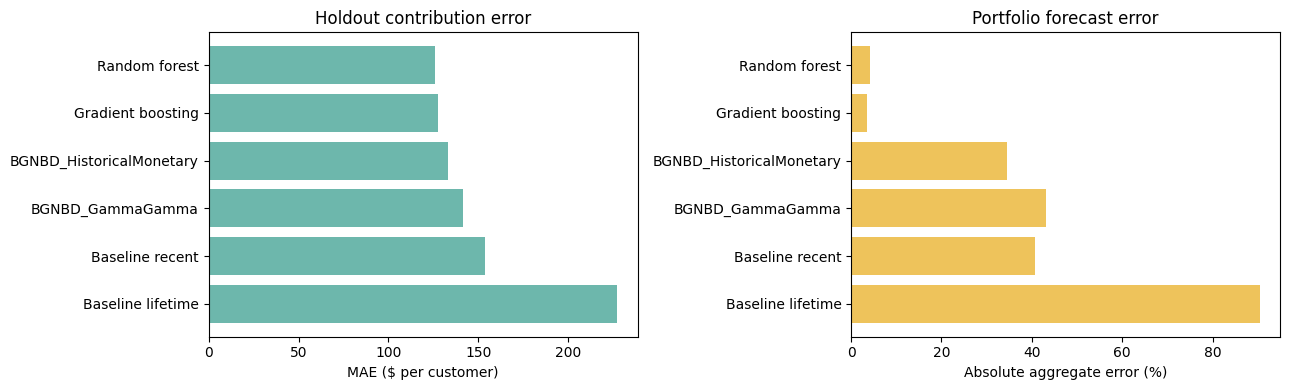

In [12]:
contrib = results.loc[results.Target=='2025 contribution ($)'].sort_values('MAE')
fig, axes = plt.subplots(1,2,figsize=(13,4))
axes[0].barh(contrib.Model,contrib.MAE,color='#6db7ac')
axes[0].invert_yaxis();axes[0].set(xlabel='MAE ($ per customer)',title='Holdout contribution error')
axes[1].barh(contrib.Model,contrib['Aggregate absolute % error'],color='#eec35b')
axes[1].invert_yaxis();axes[1].set(xlabel='Absolute aggregate error (%)',title='Portfolio forecast error')
plt.tight_layout();plt.show()

## 8. Explain probabilistic-model errors before selecting a winner
BG/NBD predicts **purchase occasions**, while Gamma-Gamma estimates expected **contribution per repeat occasion**. A contribution forecast can be wrong because the model expects too many purchases, too much contribution per purchase, or both. We compare aggregate quantities without using holdout outcomes to fit or tune either model. The decomposition is **descriptive, not causal**: multiplying two aggregate averages does not reproduce every customer's forecast, and differences in customer-level weighting create an interaction.

The BG/NBD calendar-day convention treats transactions on the same customer-day as one occasion. Because the simulation creates transactions rather than real-world shopping baskets, this is an approximation. We compare against the same occasion definition in the holdout.

In [13]:
# Reconcile count and contribution predictions without 2025-based model adjustments.
actual_occasions = float(preds.actual_purchase_occasions.sum())
pred_occasions = float(preds.BGNBD_occasions.sum())
actual_contribution = float(preds.actual_contribution.sum())
pred_contribution = float(preds.BGNBD_GammaGamma_contribution.sum())
obs_dollars_per_occ = actual_contribution / actual_occasions
implied_pred_dollars_per_occ = pred_contribution / pred_occasions

breakdown = pd.DataFrame([
    {'Measure':'Purchase occasions', 'Observed':actual_occasions, 'Predicted':pred_occasions,
     'Signed % error':100*(pred_occasions/actual_occasions-1)},
    {'Measure':'Contribution per occasion ($)', 'Observed':obs_dollars_per_occ,
     'Predicted':implied_pred_dollars_per_occ,
     'Signed % error':100*(implied_pred_dollars_per_occ/obs_dollars_per_occ-1)},
    {'Measure':'Total contribution ($)', 'Observed':actual_contribution,
     'Predicted':pred_contribution,
     'Signed % error':100*(pred_contribution/actual_contribution-1)},
])
display(breakdown.round(3))
breakdown.to_csv(OUTPUT/'probabilistic_error_decomposition.csv',index=False)
assert abs(actual_occasions-7952)<1e-7  # Reconfirm frozen occasion definition.
assert np.isfinite(breakdown[['Observed','Predicted','Signed % error']]).all().all()
print('BG/NBD fitted coefficients:', {k:round(float(v),4) for k,v in bgf.params_.items()})
print('Gamma-Gamma fitted coefficients:', {k:round(float(v),4) for k,v in ggf.params_.items()})
print('Calibration exposure T range:', round(summ['T'].min()), 'to', round(summ['T'].max()),'days')
print('Forecast window:', HORIZON_DAYS, 'days from end of calibration to end of holdout')


,Measure,Observed,Predicted,Signed % error
0,Purchase occasions,7952.000,10760.432,35.317
1,Contribution per occasion ($),51.364,54.358,5.829
2,Total contribution ($),408446.840,584916.021,43.205


BG/NBD fitted coefficients: {'r': 0.4092, 'alpha': 14.5869, 'a': 0.07, 'b': 0.2518}
Gamma-Gamma fitted coefficients: {'p': 1.1766, 'q': 0.2879, 'v': 1.1255}
Calibration exposure T range: 184 to 1095 days
Forecast window: 365 days from end of calibration to end of holdout


In [14]:
# Exploratory hybrid vs Gamma-Gamma: same BG/NBD purchase counts, different monetary estimates.
monetary_comparison = pd.DataFrame([
    {'Model': name, 'Predicted occasions': float(preds.BGNBD_occasions.sum()),
     'Implied contribution per predicted occasion': float(preds[col].sum()/preds.BGNBD_occasions.sum()),
     'Predicted portfolio contribution': float(preds[col].sum()),
     'Actual portfolio contribution':float(preds.actual_contribution.sum()),
     'Signed portfolio error %':100*(preds[col].sum()/preds.actual_contribution.sum()-1)}
    for name,col in [('BG/NBD + Gamma-Gamma','BGNBD_GammaGamma_contribution'),
                     ('BG/NBD + historical monetary (exploratory)',
                      'BGNBD_HistoricalMonetary_contribution')]
])
print('Monetary decomposition: same purchase forecasts, different contribution model')
display(monetary_comparison.round(2))
monetary_comparison.to_csv(OUTPUT/'exploratory_monetary_comparison_2025.csv',index=False)


Monetary decomposition: same purchase forecasts, different contribution model


,Model,Predicted occasions,Implied contribution per predicted occasion,Predicted portfolio contribution,Actual portfolio contribution,Signed portfolio error %
0,BG/NBD + Gamma-Gamma,10760.43,54.36,584916.02,408446.84,43.20
1,BG/NBD + historical monetary (exploratory),10760.43,51.05,549282.45,408446.84,34.48


## 9. Residuals and where forecast errors concentrate
A low aggregate error can result from positive and negative customer errors canceling. We examine customer-level prediction-versus-observation and residuals, and compare contribution errors across **historical** value groups (which do not use 2025 outcomes). The diagonal in the scatter plot marks perfect predictions; it is a reference, not a fitted line.

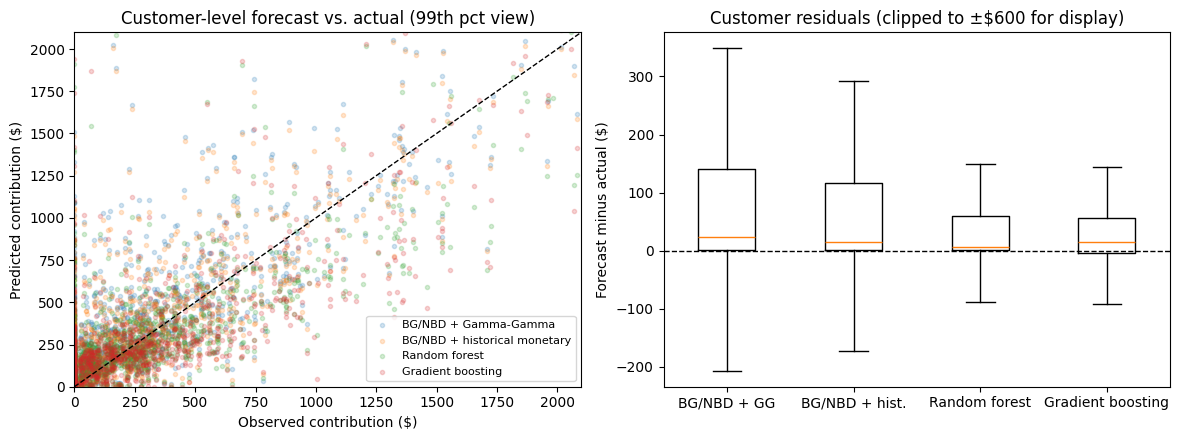

Charts omit extreme points from view only; numerical metrics use all observations.


In [15]:
# Customer-level residuals: forecast minus observed contribution.
contrib_cols = [c for c in preds if c.endswith('_contribution') and c!='actual_contribution']
residuals = pd.DataFrame({'customer_id':preds.customer_id, 'actual_contribution':preds.actual_contribution})
for c in contrib_cols:
    residuals[c.replace('_contribution','')+'_residual'] = preds[c]-preds.actual_contribution
residuals.to_csv(OUTPUT/'customer_residuals_2025.csv',index=False)
fig, axes = plt.subplots(1,2,figsize=(12,4.5))
for label,c in [('BG/NBD + Gamma-Gamma','BGNBD_GammaGamma_contribution'),
                ('BG/NBD + historical monetary','BGNBD_HistoricalMonetary_contribution'),
                ('Random forest','Random forest_contribution'),
                ('Gradient boosting','Gradient boosting_contribution')]:
    axes[0].scatter(preds.actual_contribution,preds[c],s=9,alpha=.20,label=label)
maxv = np.percentile(np.r_[preds.actual_contribution.values,
                            preds[contrib_cols].to_numpy().ravel()],99)
axes[0].plot([0,maxv],[0,maxv],linestyle='--',color='black',linewidth=1)
axes[0].set(xlim=(0,maxv),ylim=(0,maxv),xlabel='Observed contribution ($)',
            ylabel='Predicted contribution ($)',title='Customer-level forecast vs. actual (99th pct view)')
axes[0].legend(fontsize=8)
labels=['BG/NBD + GG','BG/NBD + hist.','Random forest','Gradient boosting']
cols=['BGNBD_GammaGamma_contribution','BGNBD_HistoricalMonetary_contribution',
      'Random forest_contribution','Gradient boosting_contribution']
axes[1].boxplot([(preds[c]-preds.actual_contribution).clip(-600,600) for c in cols],
                tick_labels=labels,showfliers=False)
axes[1].axhline(0,color='black',linestyle='--',linewidth=1)
axes[1].set(ylabel='Forecast minus actual ($)', title='Customer residuals (clipped to ±$600 for display)')
plt.tight_layout();plt.show()
print('Charts omit extreme points from view only; numerical metrics use all observations.')


## 10. Bootstrap uncertainty for evaluation metrics
We use a **customer-level nonparametric bootstrap**, resampling customers with replacement while keeping their observed outcomes and fixed forecasts together. It illustrates sensitivity of MAE and portfolio errors to the sampled customers. These are **not** model-training confidence intervals or proof of performance on real businesses. Because the dataset comes from one synthetic simulation and one calendar holdout, the intervals do not capture uncertainty across industries, years, or alternate simulated worlds. No model is retuned based on these intervals.

In [16]:
# Reproducible customer-level bootstrap. Keep model forecasts fixed.
rng = np.random.default_rng(SEED + 2)
B = 600
actual = preds.actual_contribution.to_numpy(float)
compare_cols = ['Baseline lifetime_contribution','Baseline recent_contribution',
                'BGNBD_GammaGamma_contribution','BGNBD_HistoricalMonetary_contribution',
                'Random forest_contribution',
                'Gradient boosting_contribution']
assert all(c in preds for c in compare_cols)
forecast = np.column_stack([preds[c].to_numpy(float) for c in compare_cols])
assert np.isfinite(forecast).all() and np.isfinite(actual).all()
boot_mae=np.empty((B,len(compare_cols)))
boot_portfolio=np.empty((B,len(compare_cols)))
for b in range(B):
    idx=rng.integers(0,len(actual),size=len(actual))
    errs=forecast[idx]-actual[idx,None]
    boot_mae[b]=np.abs(errs).mean(axis=0)
    boot_portfolio[b]=100*errs.sum(axis=0)/max(actual[idx].sum(),1e-9)
ci=[]
for j,col in enumerate(compare_cols):
    ci.append({'Model':col.replace('_contribution',''),
               'MAE observed':float(np.mean(np.abs(forecast[:,j]-actual))),
               'MAE CI 2.5%':np.quantile(boot_mae[:,j],.025),
               'MAE CI 97.5%':np.quantile(boot_mae[:,j],.975),
               'Signed portfolio error observed %':100*(forecast[:,j].sum()/actual.sum()-1),
               'Signed portfolio error CI 2.5%':np.quantile(boot_portfolio[:,j],.025),
               'Signed portfolio error CI 97.5%':np.quantile(boot_portfolio[:,j],.975)})
ci=pd.DataFrame(ci).sort_values('MAE observed')
display(ci.round(2))
ci.to_csv(OUTPUT/'bootstrap_metric_intervals_2025.csv',index=False)
rf_idx=compare_cols.index('Random forest_contribution')
bg_idx=compare_cols.index('BGNBD_GammaGamma_contribution')
delta=boot_mae[:,bg_idx]-boot_mae[:,rf_idx]
print('Paired bootstrap BG/NBD+GG minus RF MAE difference ($/customer), 95% interval:',
      np.round(np.quantile(delta,[.025,.5,.975]),2))


,Model,MAE observed,MAE CI 2.5%,MAE CI 97.5%,Signed portfolio error observed %,Signed portfolio error CI 2.5%,Signed portfolio error CI 97.5%
4,Random forest,125.66,114.63,137.94,4.28,-2.40,11.74
5,Gradient boosting,127.71,116.53,140.51,3.48,-3.13,10.60
3,BGNBD_HistoricalMonetary,133.03,124.09,142.17,34.48,28.15,41.04
2,BGNBD_GammaGamma,141.53,132.14,151.51,43.20,36.21,50.51
1,Baseline recent,153.76,143.02,164.87,40.71,32.82,48.69
0,Baseline lifetime,227.11,213.51,240.09,90.41,79.02,102.64


Paired bootstrap BG/NBD+GG minus RF MAE difference ($/customer), 95% interval: [ 5.65 16.24 24.97]


## 11. Segment diagnostics and sensitivity to high-value customers
We report error by **profile segment** and by **observed calibration-value tertile** (defined before looking at the 2025 outcome). We also report portfolio contribution error for the top 10% of customers ranked by *calibration* contribution. Avoid selecting segments using the very 2025 outcomes we're trying to forecast.

In [17]:
rank = X_hold[['customer_id','contribution']].copy()
rank['historical_band'] = pd.qcut(rank.contribution.rank(method='first'),3,labels=['Low','Middle','High'])
preds = preds.merge(rank[['customer_id','historical_band','contribution']],on='customer_id')
segments=[]
for grouping in ['segment','historical_band']:
    for name,g in preds.groupby(grouping,observed=True):
        for col in [c for c in preds if c.endswith('_contribution') and c!='actual_contribution']:
            segments.append({'Group dimension':grouping,'Group':str(name),'Customers':len(g),
                             'Model':col.replace('_contribution',''),**metrics(g.actual_contribution,g[col])})
segments=pd.DataFrame(segments)
display(segments[['Group dimension','Group','Customers','Model','MAE','Aggregate absolute % error']].round(2))
segments.to_csv(OUTPUT/'segment_metrics_2025.csv',index=False)
cut = preds.contribution.quantile(.90)
top = preds.loc[preds.contribution>=cut]
print('Top historical decile:',len(top),'| true 2025 contribution:',round(top.actual_contribution.sum(),2))
display(pd.DataFrame([{'Model':c.replace('_contribution',''),**metrics(top.actual_contribution,top[c])}
   for c in preds if c.endswith('_contribution') and c!='actual_contribution']).round(2))

,Group dimension,Group,Customers,Model,MAE,Aggregate absolute % error
0,segment,Enthusiast,278,Baseline lifetime,469.57,57.49
1,segment,Enthusiast,278,Baseline recent,357.76,26.22
2,segment,Enthusiast,278,BGNBD_GammaGamma,281.50,23.52
3,segment,Enthusiast,278,BGNBD_HistoricalMonetary,277.49,20.71
4,segment,Enthusiast,278,Random forest,330.99,0.02
5,segment,Enthusiast,278,Gradient boosting,324.13,4.37
6,segment,Occasional,990,Baseline lifetime,157.83,174.54
7,segment,Occasional,990,Baseline recent,95.73,77.57
8,segment,Occasional,990,BGNBD_GammaGamma,103.23,93.81
9,segment,Occasional,990,BGNBD_HistoricalMonetary,90.86,66.66


Top historical decile: 200 | true 2025 contribution: 182707.14


,Model,MAE,RMSE,Actual total,Predicted total,Signed total error,Aggregate absolute % error
0,Baseline lifetime,630.68,888.98,182707.14,279706.60,96999.46,53.09
1,Baseline recent,494.21,731.71,182707.14,236941.97,54234.83,29.68
2,BGNBD_GammaGamma,413.29,622.51,182707.14,230103.90,47396.76,25.94
3,BGNBD_HistoricalMonetary,408.88,613.53,182707.14,226084.90,43377.76,23.74
4,Random forest,468.69,869.85,182707.14,176428.39,-6278.75,3.44
5,Gradient boosting,460.64,863.41,182707.14,178738.75,-3968.39,2.17


## 12. Optional evaluation-only truth: activity status
The simulation's latent variables must never enter the predictive feature table or model fitting. If `simulation_ground_truth.csv` is supplied, this section inspects whether the forecast results differ for customers who truly survived to the end of 2025. This is **descriptive model auditing**, not a fair operating-time segmentation available to real retailers.

In [18]:
truth_path = INPUT/'simulation_ground_truth.csv'
if truth_path.exists():
    truth = pd.read_csv(truth_path)
    audit = preds[['customer_id','actual_contribution']].merge(truth[['customer_id','active_at_holdout_end']],on='customer_id')
    print('Evaluation only: mean observed 2025 contribution by actual simulated survival')
    display(audit.groupby('active_at_holdout_end').actual_contribution.agg(['size','mean','sum']).round(2))
else:
    print('No simulator truth file supplied. That is fine: the prediction experiment is complete without it.')

Evaluation only: mean observed 2025 contribution by actual simulated survival


,size,mean,sum
active_at_holdout_end,,,
False,1381,51.25,70780.82
True,619,545.50,337666.02


## 13. Conclusions, limitations, and reproducibility
**Interpret the actual result table above rather than assuming the advanced approach wins.**

- **Baseline challenge:** Regular purchasing and cohort decline can make naïve run rates overforecast customer contributions.
- **Model misspecification:** BG/NBD assumes a particular repeat-purchase and dropout process; the simulator includes seasonality and segment differences. Gamma-Gamma further assumes relatively independent purchase frequency and transaction value. Check the correlation printout.
- **Different event units:** Same-day transactions are aggregated into occasions for BG/NBD. Its occasion forecast must not be compared directly with raw transaction counts. All approaches can still be compared on dollar contribution.
- **Time-aware ML:** ML is trained on the 2023→2024 origin, tested on the 2024→2025 origin. This limited temporal validation does not guarantee generalization.
- **Interpretation:** No single model is universally best. Segment and portfolio forecasting quality matter alongside MAE and RMSE. Forecast errors are not causal effects or real-business benchmarks.
- **Contribution accounting:** Values are contribution after variable costs, **not net profit**, and not discounted present value. Referral and advocacy contributions are not modeled here.

**Article handoff:** Use `model_metrics_2025.csv`, `segment_metrics_2025.csv`, and the figures to report the observed comparison. Do not invent performance claims.

**Modeling caveat:** BG/NBD predictions are for repeat occasions, whereas baseline and ML purchase predictions count raw transactions. Only the contribution forecasts are directly comparable across all methods in the same target table. The zero-repeat Gamma-Gamma fallback uses historical calibration data and should not be mistaken for a fitted monetary estimate for those customers.

**Methodological cautions for publication:** (1) Calendar-day occasions are not the same as raw transactions; (2) the Gamma-Gamma fallback for customers without repeat purchases is an empirical assumption; (3) the weak frequency/value association merits qualification rather than a blanket independence claim; (4) results come from a single simulated setting and a single untouched holdout, not a universal model ranking; (5) signed portfolio errors can cancel even when customer-level errors are large; (6) the probabilistic models fit purchase histories through 2024, while supervised ML learns a 2024 training target from an earlier origin. The procedures differ even though all forecasts are evaluated on the identical 2025 customers.


**Exploratory follow-up:** The BG/NBD × historical monetary hybrid was added after studying the holdout and is not part of a preregistered comparison. Its 2025 results are descriptive. An independent synthetic replication or a new temporal holdout would be needed to test its added value without selection bias. Gamma-Gamma q < 1 and monetary penalizer sensitivity warrant explicit reporting.

**Publication-ready sensitivity record:** Section 5 contains calibration-only BG/NBD and Gamma-Gamma penalizer tables, checks for warnings and nonfinite predictions, and a clearly labeled post-hoc monetary validation against future purchasers. Retaining BG/NBD 1.0 is a numerical-stability decision, **not** evidence of optimal holdout accuracy. Gamma-Gamma 0.10 is the original configuration, not a holdout-selected winner; `q ≤ 1` and monetary prediction sensitivity limit interpretation. The separate hybrid is an exploratory post-hoc comparison.


In [19]:
manifest = {'random_seed':SEED,'calibration_end':str(CAL_END.date()),'holdout_end':str(HOLD_END.date()),
            'ML_train_origin':'2023-12-31','ML_train_target':'calendar 2024',
            'forecast_population':'2000 existing customers','simulator_truth_used_as_features':False,
            'same_day_BG_NBD_handling':'aggregate to customer-date occasions',
            'notebook_version':'v5', 'bootstrap_draws':600,
            'GG_no_repeat_fallback':'mean observed repeat-occasion contribution of eligible customers',
            'holdout_used_for_model_tuning':False,
            'post_hoc_exploratory_hybrid_added_after_2025_review':True,
            'hybrid_zero_repeat_monetary':'first calibration occasion; population mean last fallback',
            'BGNBD_regularization_sensitivity':[0.01,0.05,0.10,0.25,0.50,1.0,2.0],
            'GammaGamma_regularization_sensitivity':[0.01,0.05,0.10,0.20,0.50],
            'GammaGamma_holdout_monetary_diagnostic':'post hoc; not used for model selection'}
(OUTPUT/'experiment_manifest.json').write_text(json.dumps(manifest,indent=2))
print('Outputs:',[(p.name,round(p.stat().st_size/1024,1)) for p in OUTPUT.iterdir() if p.is_file()])
if Path('/content').exists():
    import shutil
    archive = shutil.make_archive('/content/clv_model_results','zip',OUTPUT)
    print('For download:',archive)

Outputs: [('exploratory_monetary_comparison_2025.csv', 0.4), ('bootstrap_metric_intervals_2025.csv', 0.9), ('bgnbd_regularization_sensitivity.csv', 0.9), ('experiment_manifest.json', 1.0), ('segment_metrics_2025.csv', 5.2), ('gamma_gamma_holdout_monetary_diagnostic_POST_HOC.csv', 0.7), ('gamma_gamma_regularization_sensitivity.csv', 0.9), ('customer_predictions_2025.csv', 435.3), ('model_metrics_2025.csv', 1.6), ('customer_residuals_2025.csv', 224.6), ('probabilistic_error_decomposition.csv', 0.3)]
For download: /content/clv_model_results.zip
